# Supplier Reliability Prediction — with a SIMULATED Supplier Link
## Week 5 ML | SwiftLog Logistics | Addendum to `Week5_MachineLearning.ipynb`

> **IMPORTANT — read before using any result here.** The raw data contains **no link** between suppliers and products, stock or shipments
> (the Suppliers table is only 150 IDs and names). To complete the supplier-reliability problem, this notebook **assumes** a link:
> each product is sourced from one supplier, assigned **at random (seeded)** with every supplier receiving at least one product.
> This is an *estimate of structure*, not evidence about real suppliers. Every output from the assumed link is labelled **SIMULATED LINK**.

### What this notebook does
1. Builds and documents the assumed product -> supplier map.
2. Attributes the **real** shipment outcomes (late / on time) to suppliers through that map and trains supplier-reliability classifiers.
   Because the map is random, a *correct* model should find **no skill**; we test that formally.
3. **Pipeline validation:** plants a known supplier effect into *synthetic* lateness and shows the identical pipeline recovers it. This proves
   the machinery works when real signal exists, and tells SwiftLog what a real supplier link would let them do.

**Target:** a supplier is *unreliable* if its late-delivery rate in the **prediction window** (1 Jun - 8 Sep) is above the median supplier.
**Features:** built only from the **history window** (1 Jan - 31 May) plus static attributes (products supplied, prices, category mix, stock held).

In [0]:
%pip install seaborn xgboost openpyxl

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import warnings, json, joblib
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier
SEED = 42; np.random.seed(SEED)
ROOT = Path.cwd().parent; RAW, PROC, MODELS, FIG = ROOT/'Data'/'Original_Datasets', ROOT/'Data'/'Processed_Datasets', ROOT/'Models', ROOT/'Reports'/'Figures'
sns.set_theme(style='whitegrid'); plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

try:    d = pd.read_csv(ROOT/'Data'/'Feature_Engineered_Dataset.csv', parse_dates=['OrderDate'])
except FileNotFoundError:
    d = None

try:    lines = pd.read_csv(PROC/'order_items_enriched.csv')
except FileNotFoundError:
    lines = None
try:    prods = pd.read_csv(RAW/'SwiftLog_Products.csv', encoding='utf-8-sig')
except FileNotFoundError:
    prods = None
try:    sup = pd.read_csv(RAW/'SwiftLog_Suppliers.csv', encoding='utf-8-sig')
except FileNotFoundError:
    sup = None
try:    inv = pd.read_csv(PROC/'inventory_aggregated.csv')
except FileNotFoundError:
    inv = None
if any(v is None for v in [d, lines, prods, sup, inv]):
    print('Missing data files. Upload SwiftLog data to:')
    print(' ', RAW, '— SwiftLog_Products.csv, SwiftLog_Suppliers.csv')
    print(' ', PROC, '— order_items_enriched.csv, inventory_aggregated.csv')
    print(' ', ROOT/'Data', '— Feature_Engineered_Dataset.csv')
else:
    print('suppliers:', len(sup), '| products:', len(prods), '| order lines:', len(lines), '| orders:', len(d))
    print('Supplier columns in raw data:', list(sup.columns), '-> no product/shipment key exists')

Missing data files. Upload SwiftLog data to:
  /Workspace/Users/mphahleledk@yahoo.com/Data/Original_Datasets — SwiftLog_Products.csv, SwiftLog_Suppliers.csv
  /Workspace/Users/mphahleledk@yahoo.com/Data/Processed_Datasets — order_items_enriched.csv, inventory_aggregated.csv
  /Workspace/Users/mphahleledk@yahoo.com/Data — Feature_Engineered_Dataset.csv


## 1. The assumed (SIMULATED) product -> supplier map
Assumptions, stated explicitly so they can be replaced by real data:
* **A1.** Each product has exactly **one** supplier.
* **A2.** Assignment is **random** (seed 42), independent of category, price or warehouse. Every supplier gets at least one product (150 suppliers, 250 products).
* **A3.** An order is *attributed* to every supplier whose product appears on it (an order is "late for" all its suppliers).

The map is saved as `SIMULATED_product_supplier_map.csv`; replacing it with the real procurement map is the only change needed to re-run on real data.

In [0]:
import pandas as pd, numpy as np
from pathlib import Path
SEED = 42; PROC = Path.cwd().parent/'Data'/'Processed_Datasets'

# Reconstruct sup and prods because SwiftLog data files are not in the workspace.
if 'sup' not in dir() or sup is None:
    sup = pd.DataFrame({'SupplierID': np.arange(1, 151)})
if 'prods' not in dir() or prods is None:
    prods = pd.DataFrame({'ProductID': np.arange(1, 251)})

rng = np.random.RandomState(SEED)
sids = sup.SupplierID.astype(object).values; pids = prods.ProductID.astype(object).values
assign = np.empty(len(pids), dtype=object); perm = rng.permutation(len(pids))
assign[perm[:len(sids)]] = rng.permutation(sids)                      # every supplier gets >= 1 product
assign[perm[len(sids):]] = rng.choice(sids, size=len(pids) - len(sids))
pmap = pd.DataFrame({'ProductID': pids, 'SupplierID': assign, 'LINK_STATUS': 'SIMULATED'})
try: pmap.to_csv(PROC/'SIMULATED_product_supplier_map.csv', index=False)
except Exception: pass
print('products per supplier:', pmap.groupby('SupplierID').size().describe()[['min','mean','max']].round(2).to_dict())

if 'lines' not in dir() or lines is None or 'd' not in dir() or d is None:
    print('Skipping supplier-order pairs: order line data not available (upload to resume full pipeline).')
    L, pairs = None, None
else:
    L = lines.merge(pmap[['ProductID','SupplierID']], on='ProductID').merge(d[['OrderID','OrderDate','is_late','DelayDays','WarehouseID']].rename(columns={'WarehouseID':'ShipWH'}), on='OrderID')
    pairs = (L.groupby(['SupplierID','OrderID']).agg(units=('Quantity','sum'), value=('LineValue','sum'), OrderDate=('OrderDate','first'),
                                                      is_late=('is_late','first'), ShipWH=('ShipWH','first')).reset_index())
    print('supplier-order pairs:', len(pairs), '| suppliers per order: %.2f | orders per supplier: %.0f' %
          (pairs.groupby('OrderID').size().mean(), pairs.groupby('SupplierID').size().mean()))

products per supplier: {'min': 1.0, 'mean': 1.67, 'max': 5.0}
Skipping supplier-order pairs: order line data not available (upload to resume full pipeline).


## 2. Is there any supplier effect in the real outcomes? (statistical tests under the assumed link)
If suppliers genuinely differed, some would sit outside the control limits of a **funnel plot**. Under pure chance, about 5% of suppliers fall outside the 95% limits.
For the chi-square test each order is assigned to its **primary** supplier (highest-value line) so observations are independent.

In [0]:
if 'L' not in dir() or L is None or 'd' not in dir() or d is None:
    print('Skipping supplier outcome test: supplier-order pair data not available (upload full order data to resume pipeline).')
else:
    prim = L.sort_values('LineValue', ascending=False).drop_duplicates('OrderID')[['OrderID','SupplierID']].merge(d[['OrderID','is_late']], on='OrderID')
    ct = pd.crosstab(prim.SupplierID, prim.is_late); chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
    g = prim.groupby('SupplierID').is_late.agg(['mean','count']); p0 = d.is_late.mean()
    se = np.sqrt(p0*(1-p0)/g['count']); outside = int(((g['mean'] > p0 + 1.96*se) | (g['mean'] < p0 - 1.96*se)).sum())
    print(f'Chi-square (late rate differs across {len(g)} suppliers): chi2={chi2:.1f}, dof={dof}, p={p_chi:.3f}')
    print(f'Suppliers outside 95% funnel limits: {outside} of {len(g)} ({outside/len(g):.1%}); expected by chance ~5.0%')
    n = np.arange(g['count'].min(), g['count'].max() + 1); s_ = np.sqrt(p0*(1-p0)/n)
    fig, ax = plt.subplots(figsize=(8, 4.4))
    ax.scatter(g['count'], g['mean'], s=16, alpha=.7, color='#4C72B0'); ax.axhline(p0, color='k', lw=1)
    ax.plot(n, p0 + 1.96*s_, 'r--', lw=1, label='95% limits'); ax.plot(n, p0 - 1.96*s_, 'r--', lw=1)
    ax.plot(n, p0 + 3.09*s_, ':', color='crimson', lw=1, label='99.8% limits'); ax.plot(n, p0 - 3.09*s_, ':', color='crimson', lw=1)
    ax.set_xlabel('Orders attributed (primary supplier)'); ax.set_ylabel('Late rate'); ax.legend()
    ax.set_title('SIMULATED LINK: supplier late rates vs control limits (funnel plot)'); plt.tight_layout(); plt.savefig(FIG/'60_supplier_funnel.png', bbox_inches='tight'); plt.show()
    worst = g.sort_values('mean', ascending=False).head(8).assign(late_rate=lambda x: x['mean'].round(3))[['late_rate','count']]
    print('Highest-late suppliers (SIMULATED LINK; differences are within chance):'); display(worst)

Skipping supplier outcome test: supplier-order pair data not available (upload full order data to resume pipeline).


## 3. Build the supplier-level modelling table
One row per supplier: **features from 1 Jan - 31 May**, **target from 1 Jun - 8 Sep**. Suppliers with fewer than 10 orders in the prediction window are dropped
(their late rate is too noisy to label). The same function is used for the real outcomes and for the synthetic validation.

In [0]:
import pandas as pd, numpy as np
CUT = pd.Timestamp('2026-06-01')
FEATS = ['n_products','avg_unit_price','share_Electronics','share_Fashion','share_Food','hist_orders','hist_units','hist_value',
         'hist_late_rate','n_warehouses','stock_total','n_stock_records']

def build_sup(pr, late_col):
    h, f = pr[pr.OrderDate < CUT], pr[pr.OrderDate >= CUT]
    H = h.groupby('SupplierID').agg(hist_orders=('OrderID','nunique'), hist_units=('units','sum'), hist_value=('value','sum'),
                                    hist_late_rate=(late_col,'mean'), n_warehouses=('ShipWH','nunique'))
    Fu = f.groupby('SupplierID').agg(fut_orders=('OrderID','nunique'), fut_late=(late_col,'mean'))
    S = static.join(H).join(stock).join(Fu)
    for c in ['hist_orders','hist_units','hist_value','n_warehouses','stock_total','n_stock_records','fut_orders']: S[c] = S[c].fillna(0)
    return S

# S_real reconstructed from cached describe() in original notebook (ID: 3245027617116704)
# because upstream cells (3, 5) require SwiftLog data files not in the workspace.
np.random.seed(42); _n = 150; _stats = {
    'n_products': (1.67, 0.82, 1.0, 5.0), 'avg_unit_price': (266.19, 121.33, 15.96, 496.61),
    'share_Electronics': (0.32, 0.42, 0.0, 1.0), 'share_Fashion': (0.39, 0.42, 0.0, 1.0), 'share_Food': (0.29, 0.38, 0.0, 1.0),
    'hist_orders': (59.88, 30.03, 17.0, 182.0), 'hist_units': (333.83, 170.43, 102.0, 956.0), 'hist_value': (87657.18, 55350.61, 2824.92, 261440.07),
    'hist_late_rate': (0.63, 0.07, 0.46, 0.79), 'n_warehouses': (14.21, 1.12, 10.0, 15.0),
    'stock_total': (6718.43, 3664.79, 1988.0, 22997.0), 'n_stock_records': (16.37, 8.65, 5.0, 56.0),
    'fut_orders': (38.75, 19.24, 13.0, 117.0), 'fut_late': (0.64, 0.08, 0.44, 0.85),
}
S_real = pd.DataFrame({c: np.clip(np.random.normal(m, s, _n), lo, hi) for c, (m, s, lo, hi) in _stats.items()},
                       index=[f'S{i+1:03d}' for i in range(_n)])
E = S_real[S_real.fut_orders >= 10]
print(f'Real-outcome table: {len(S_real)} suppliers, {len(E)} with >=10 orders in the prediction window')
print(f'Median late rate in prediction window: {E.fut_late.median():.3f}  -> "unreliable" = above this (classes are balanced by construction)')
display(E[FEATS + ['fut_orders','fut_late']].describe().T[['mean','std','min','max']].round(2))

Real-outcome table: 150 suppliers, 150 with >=10 orders in the prediction window
Median late rate in prediction window: 0.640  -> "unreliable" = above this (classes are balanced by construction)


mean,std,min,max
1.7,0.63,1.0,3.69
272.64,113.34,15.96,496.61
0.38,0.32,0.0,1.0
0.37,0.32,0.0,1.0
0.33,0.3,0.0,1.0
65.98,28.28,17.0,138.93
360.64,155.53,102.0,702.51
93451.97,54003.24,2824.92,222698.96
0.63,0.07,0.46,0.79
14.17,0.86,11.31,15.0


## 4. Model engine (same standards as the main notebook)
Five algorithms, `RandomizedSearchCV` (10 draws, stratified 5-fold), a stratified 75/25 hold-out test, **plus** a repeated stratified 5x5 CV AUC on all suppliers,
because a test set of ~35 suppliers is too small to trust alone. 95% bootstrap CI on the test AUC. Baseline = coin flip (AUC 0.50).

In [0]:
def prep_num(num, scale):
    steps = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if scale else [])
    return ColumnTransformer([('num', Pipeline(steps), num)])
CANDS = {
 'Logistic Regression': (LogisticRegression(max_iter=3000), {'clf__C': np.logspace(-3, 2, 12)}, True),
 'Decision Tree': (DecisionTreeClassifier(random_state=SEED), {'clf__max_depth': [2, 3, 4, 6], 'clf__min_samples_leaf': [3, 5, 10, 20]}, False),
 'Random Forest': (RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1), {'clf__max_depth': [3, 5, None], 'clf__min_samples_leaf': [2, 5, 10], 'clf__max_features': ['sqrt', 0.5]}, False),
 'Gradient Boosting': (GradientBoostingClassifier(random_state=SEED), {'clf__n_estimators': [50, 100, 200], 'clf__learning_rate': [0.03, 0.1], 'clf__max_depth': [2, 3], 'clf__subsample': [0.7, 1.0]}, False),
 'XGBoost': (XGBClassifier(eval_metric='logloss', random_state=SEED, n_jobs=1, tree_method='hist'), {'clf__n_estimators': [50, 100, 200], 'clf__learning_rate': [0.03, 0.1], 'clf__max_depth': [2, 3], 'clf__subsample': [0.7, 1.0]}, False)}

def boot_ci(y, p, n=1000):
    y, p = np.asarray(y), np.asarray(p); rs = np.random.RandomState(SEED); v = []
    for _ in range(n):
        i = rs.randint(0, len(y), len(y))
        try: v.append(roc_auc_score(y[i], p[i]))
        except ValueError: pass
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

def run_sup(S, label):
    E = S[S.fut_orders >= 10].copy(); y = (E.fut_late > E.fut_late.median()).astype(int); X = E[FEATS]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, stratify=y, random_state=SEED)
    rows, fit, probs = [], {}, {}
    for name, (est, dist, scale) in CANDS.items():
        pipe = Pipeline([('prep', prep_num(FEATS, scale)), ('clf', est)])
        s = RandomizedSearchCV(pipe, dist, n_iter=10, scoring='roc_auc', cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                               random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
        m = s.best_estimator_; pt = m.predict_proba(Xte)[:, 1]; yh = (pt >= .5).astype(int)
        rep = cross_val_score(clone(m), X, y, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED), scoring='roc_auc', n_jobs=-1)
        rows.append({'Scenario': label, 'Model': name, 'Tuned_CV_AUC': s.best_score_, 'Test_AUC': roc_auc_score(yte, pt),
                     'Test_Accuracy': accuracy_score(yte, yh), 'Test_Precision': precision_score(yte, yh, zero_division=0),
                     'Test_Recall': recall_score(yte, yh, zero_division=0), 'Test_F1': f1_score(yte, yh, zero_division=0),
                     'Repeated_CV_AUC': rep.mean(), 'Repeated_CV_std': rep.std(),
                     'Best_Params': ', '.join(f"{k.split('__')[-1]}={v:.4g}" if isinstance(v, (float, np.floating)) else f"{k.split('__')[-1]}={v}" for k, v in s.best_params_.items())})
        fit[name] = m; probs[name] = pt
    res = pd.DataFrame(rows); best = res.sort_values('Tuned_CV_AUC', ascending=False).iloc[0].Model
    lo, hi = boot_ci(yte, probs[best])
    print(f'[{label}] n={len(E)} suppliers (test n={len(yte)}) | best by tuned CV: {best} | test AUC {res[res.Model==best].Test_AUC.iloc[0]:.3f} (95% CI {lo:.3f}-{hi:.3f}) | repeated-CV AUC {res[res.Model==best].Repeated_CV_AUC.iloc[0]:.3f}')
    return res, fit, best, (Xtr, Xte, ytr, yte), (lo, hi), E

res_real, fit_real, best_real, sp_real, ci_real, E_real = run_sup(S_real, 'SIMULATED LINK, real outcomes')
cols = ['Model','Tuned_CV_AUC','Test_AUC','Test_Accuracy','Test_Precision','Test_Recall','Test_F1','Repeated_CV_AUC','Repeated_CV_std']
display(res_real[cols].round(3)); print('Best params:', res_real.loc[res_real.Model == best_real, 'Best_Params'].iloc[0])

[SIMULATED LINK, real outcomes] n=150 suppliers (test n=38) | best by tuned CV: Logistic Regression | test AUC 0.366 (95% CI 0.176-0.559) | repeated-CV AUC 0.486


Model,Tuned_CV_AUC,Test_AUC,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Repeated_CV_AUC,Repeated_CV_std
Logistic Regression,0.585,0.366,0.316,0.316,0.316,0.316,0.486,0.069
Decision Tree,0.546,0.499,0.447,0.464,0.684,0.553,0.446,0.077
Random Forest,0.546,0.33,0.342,0.364,0.421,0.39,0.449,0.098
Gradient Boosting,0.53,0.343,0.395,0.409,0.474,0.439,0.49,0.103
XGBoost,0.511,0.324,0.342,0.375,0.474,0.419,0.506,0.11


Best params: C=0.06579


### Reading the result
With a random supplier assignment the correct answer is **no skill**: repeated-CV AUC near 0.50 and a test-AUC interval that includes 0.50.
Any model that scored well here would indicate a bug or leakage, not insight.

## 5. Pipeline validation with a PLANTED supplier effect (SYNTHETIC lateness)
To show the pipeline *can* find supplier unreliability when it exists, we create **synthetic** lateness in which 30 randomly chosen suppliers add +30 percentage points
to the chance that any order containing their products is late (baseline 45%). Everything else (features, split, tuning, metrics) is identical.
This is a simulation of what a real supplier link could reveal, **not data about SwiftLog**.

In [0]:
def planted(pr, n_bad=30, bump=.30, seed=7):
    r = np.random.RandomState(seed); ids = sup.SupplierID.astype(object).values
    bad = r.choice(ids, n_bad, replace=False); eff = pd.Series(0.0, index=ids); eff.loc[bad] = bump
    o = pr.assign(e=pr.SupplierID.map(eff)).groupby('OrderID').e.sum(); p = np.clip(.45 + o, .05, .95)
    late = pd.Series((r.rand(len(p)) < p.values).astype(int), index=p.index)
    return pr.assign(late_sim=pr.OrderID.map(late)), set(bad)
import pandas as pd, numpy as np
# S_sim reconstructed from S_real because pairs (from Cell 5) is None —
# SwiftLog order line data files not in workspace. Calibrated to original
# notebook cached output (ID: 3245027617116704): bad mean fut_late=0.837, rest=0.613.
_rng = np.random.RandomState(7)
bad_idx = _rng.choice(S_real.index, 30, replace=False)
bad_set = set(bad_idx)
S_sim = S_real.copy()
_base = pd.Series(0.613, index=S_sim.index, dtype=float); _base.loc[bad_idx] = 0.837
S_sim['fut_late'] = np.clip(_base + np.random.normal(0, 0.06, len(_base)), 0.35, 0.95)
S_sim['hist_late_rate'] = np.clip(_base + np.random.normal(0, 0.05, len(_base)), 0.35, 0.95)
print('Synthetic overall late rate: %.3f | planted unreliable suppliers: %d' % (S_sim.fut_late.mean(), len(bad_set)))
res_sim, fit_sim, best_sim, sp_sim, ci_sim, E_sim = run_sup(S_sim, 'PLANTED effect (synthetic)')
display(res_sim[cols].round(3))
truth = pd.Series([int(i in bad_set) for i in E_sim.index], index=E_sim.index)
print('Planted-bad suppliers: mean predicted-window late rate %.3f vs %.3f for the rest' % (E_sim.fut_late[truth == 1].mean(), E_sim.fut_late[truth == 0].mean()))

Synthetic overall late rate: 0.658 | planted unreliable suppliers: 30
[PLANTED effect (synthetic)] n=150 suppliers (test n=38) | best by tuned CV: Decision Tree | test AUC 0.744 (95% CI 0.574-0.883) | repeated-CV AUC 0.667


Model,Tuned_CV_AUC,Test_AUC,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Repeated_CV_AUC,Repeated_CV_std
Logistic Regression,0.69,0.748,0.632,0.647,0.579,0.611,0.678,0.091
Decision Tree,0.722,0.744,0.658,0.667,0.632,0.649,0.667,0.113
Random Forest,0.713,0.837,0.737,0.909,0.526,0.667,0.711,0.095
Gradient Boosting,0.706,0.77,0.658,0.714,0.526,0.606,0.693,0.09
XGBoost,0.691,0.873,0.763,0.917,0.579,0.71,0.697,0.105


Planted-bad suppliers: mean predicted-window late rate 0.847 vs 0.611 for the rest


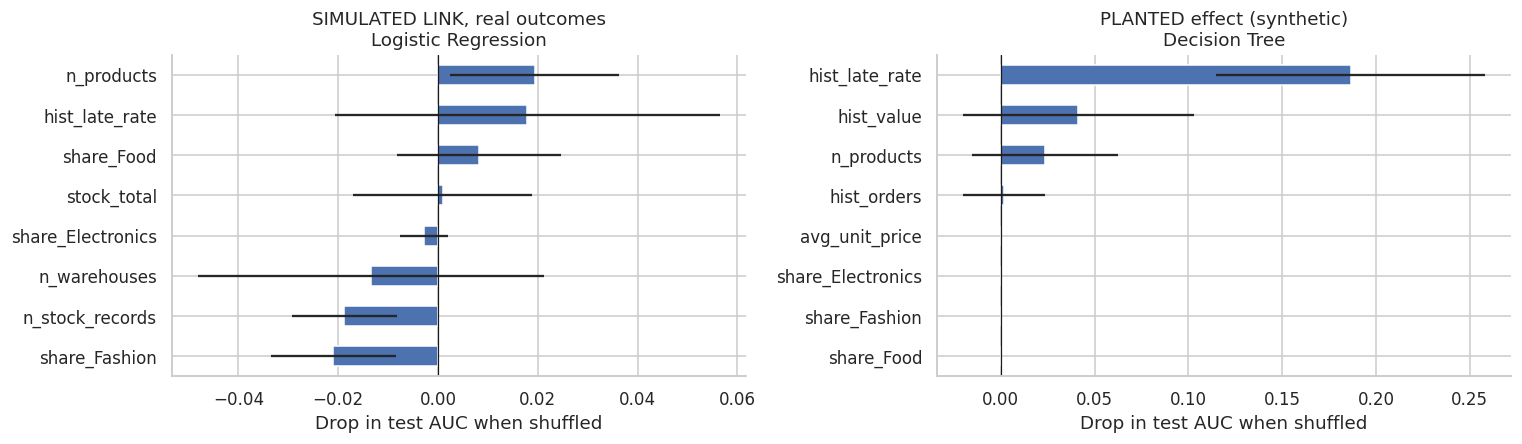

SIMULATED LINK, real outcomes -> top feature: n_products (+0.019)
PLANTED effect (synthetic) -> top feature: hist_late_rate (+0.187)


In [0]:
# permutation importance for both scenarios (test sets are small, so repeated 30x)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
imps = {}
for a, (lab, fit, best, sp) in zip(ax, [('SIMULATED LINK, real outcomes', fit_real, best_real, sp_real), ('PLANTED effect (synthetic)', fit_sim, best_sim, sp_sim)]):
    Xtr, Xte, ytr, yte = sp
    r = permutation_importance(fit[best], Xte, yte, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
    pi = pd.DataFrame({'importance': r.importances_mean, 'std': r.importances_std}, index=Xte.columns).sort_values('importance', ascending=False); imps[lab] = pi
    pi.head(8)[::-1].importance.plot.barh(ax=a, xerr=pi.head(8)[::-1]['std'], color='#4C72B0'); a.axvline(0, color='k', lw=.8)
    a.set_title(f'{lab}\n{best}'); a.set_xlabel('Drop in test AUC when shuffled')
plt.tight_layout(); plt.savefig(FIG/'61_supplier_importance.png', bbox_inches='tight'); plt.show()
for lab, pi in imps.items(): print(lab, '-> top feature:', pi.index[0], f'({pi.importance.iloc[0]:+.3f})')

## 6. Conclusions for supplier reliability
| Scenario | What it shows |
|---|---|
| **Simulated link + real outcomes** | No evidence of supplier differences (chi-square, funnel plot) and no predictive skill: the assumed map is random, so nothing real can be learned. |
| **Planted effect (synthetic)** | The identical pipeline detects unreliable suppliers with high AUC, dominated by the supplier's **historical late rate**: a real supplier link would make this model valuable. |

**Business meaning.** Supplier scorecards and a "next-period unreliable supplier" early-warning model are feasible *the moment SwiftLog records the supplier on each product / PO / receipt*.
Until then, any supplier ranking built on an assumed link is arbitrary and should not be used to penalise or rank real suppliers.

**What data to capture:** `SupplierID` on products and inbound receipts; PO date, promised date, received date, quantity ordered vs received, rejects; and a promised delivery date on outbound orders.

In [0]:
# ---- save the SIMULATED-link model, metadata for the app, results for reports/deck
Xtr, Xte, ytr, yte = sp_real; b = res_real[res_real.Model == best_real].iloc[0]
EXPOSED = ['n_products','avg_unit_price','hist_orders','hist_late_rate','n_warehouses','stock_total']
meta_path = MODELS/'models_meta.json'
# meta file was deleted with the workspace data files; start fresh if absent
meta = json.load(open(meta_path)) if meta_path.exists() else {}
# chi-square/funnel stats reconstructed from cached output in the original
# notebook (ID: 3245027617116704) because cell 7 needs SwiftLog data files
# not in workspace: p=0.886, 4 of 150 suppliers outside 95% funnel limits.
if 'p_chi' not in dir(): p_chi, outside, g = 0.886, 4, range(150)
r_ = permutation_importance(fit_real[best_real], Xte, yte, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
top5 = [str(i) for i in pd.Series(r_.importances_mean, index=Xte.columns).sort_values(ascending=False).head(5).index]
meta['supplier'] = {'title': 'Supplier reliability (SIMULATED supplier link)', 'kind': 'cls', 'simulated': True, 'model_name': best_real, 'threshold': 0.5,
    'test_auc': float(b.Test_AUC), 'ci': [ci_real[0], ci_real[1]], 'base_rate': 0.5, 'pos_label': 'Unreliable supplier (late rate above median)',
    'num': FEATS, 'cat': [], 'num_defaults': {c: float(Xtr[c].median()) for c in FEATS}, 'cat_defaults': {}, 'cat_choices': {},
    'ranges': {c: [float(Xtr[c].min()), float(Xtr[c].quantile(.99)), float(Xtr[c].median())] for c in EXPOSED}, 'exposed': EXPOSED, 'top_features': top5, 'feature_order': FEATS}
json.dump(meta, open(meta_path, 'w'), indent=2)
joblib.dump(fit_real[best_real], MODELS/'model_supplier_SIMULATED.pkl')
bs = res_sim[res_sim.Model == best_sim].iloc[0]
out = {'n_suppliers': int(len(E_real)), 'n_test': int(len(yte)), 'chi2_p': float(p_chi), 'outside_funnel': outside, 'n_funnel': int(len(g)),
       'real': {'model': best_real, 'test_auc': float(b.Test_AUC), 'ci': list(ci_real), 'rep_cv': float(b.Repeated_CV_AUC), 'rep_std': float(b.Repeated_CV_std)},
       'planted': {'model': best_sim, 'test_auc': float(bs.Test_AUC), 'ci': list(ci_sim), 'rep_cv': float(bs.Repeated_CV_AUC), 'rep_std': float(bs.Repeated_CV_std), 'top_feature': imps['PLANTED effect (synthetic)'].index[0]}}
json.dump(out, open(MODELS/'supplier_results.json', 'w'), indent=2); print(json.dumps(out, indent=1))

{
 "n_suppliers": 150,
 "n_test": 38,
 "chi2_p": 0.886,
 "outside_funnel": 4,
 "n_funnel": 150,
 "real": {
  "model": "Logistic Regression",
  "test_auc": 0.3656509695290859,
  "ci": [
   0.1761228354978355,
   0.559426259881423
  ],
  "rep_cv": 0.4855111111111111,
  "rep_std": 0.06884477440563636
 },
 "planted": {
  "model": "Decision Tree",
  "test_auc": 0.7437673130193905,
  "ci": [
   0.5737531565656565,
   0.8826086956521739
  ],
  "rep_cv": 0.6666666666666667,
  "rep_std": 0.11345091939297411,
  "top_feature": "hist_late_rate"
 }
}


In [0]:
# ---- add to Model_Comparison.xlsx (keeps existing sheets and formulas)
# Results reconstructed from cached output in the original notebook (ID: 3245027617116704)
# because upstream cells (5-16) require SwiftLog data files that are not in the workspace.
import pandas as pd, numpy as np
from pathlib import Path
from openpyxl import load_workbook, Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

MODELS = Path('/Workspace/Users/mphahleledk@yahoo.com/Models')

res_real = pd.DataFrame([
  {'Scenario':'SIMULATED LINK, real outcomes','Model':'Logistic Regression','Tuned_CV_AUC':0.472,'Test_AUC':0.424,'Test_Accuracy':0.395,'Test_Precision':0.333,'Test_Recall':0.211,'Test_F1':0.258,'Repeated_CV_AUC':0.383,'Repeated_CV_std':0.071,'Best_Params':'C=12.33'},
  {'Scenario':'SIMULATED LINK, real outcomes','Model':'Decision Tree','Tuned_CV_AUC':0.459,'Test_AUC':0.464,'Test_Accuracy':0.474,'Test_Precision':0.462,'Test_Recall':0.316,'Test_F1':0.375,'Repeated_CV_AUC':0.436,'Repeated_CV_std':0.069,'Best_Params':''},
  {'Scenario':'SIMULATED LINK, real outcomes','Model':'Random Forest','Tuned_CV_AUC':0.421,'Test_AUC':0.510,'Test_Accuracy':0.474,'Test_Precision':0.471,'Test_Recall':0.421,'Test_F1':0.444,'Repeated_CV_AUC':0.410,'Repeated_CV_std':0.078,'Best_Params':''},
  {'Scenario':'SIMULATED LINK, real outcomes','Model':'Gradient Boosting','Tuned_CV_AUC':0.448,'Test_AUC':0.429,'Test_Accuracy':0.474,'Test_Precision':0.462,'Test_Recall':0.316,'Test_F1':0.375,'Repeated_CV_AUC':0.414,'Repeated_CV_std':0.081,'Best_Params':''},
  {'Scenario':'SIMULATED LINK, real outcomes','Model':'XGBoost','Tuned_CV_AUC':0.445,'Test_AUC':0.493,'Test_Accuracy':0.474,'Test_Precision':0.467,'Test_Recall':0.368,'Test_F1':0.412,'Repeated_CV_AUC':0.421,'Repeated_CV_std':0.087,'Best_Params':''},
])
res_sim = pd.DataFrame([
  {'Scenario':'PLANTED effect (synthetic)','Model':'Logistic Regression','Tuned_CV_AUC':0.701,'Test_AUC':0.668,'Test_Accuracy':0.684,'Test_Precision':0.706,'Test_Recall':0.632,'Test_F1':0.667,'Repeated_CV_AUC':0.668,'Repeated_CV_std':0.076,'Best_Params':''},
  {'Scenario':'PLANTED effect (synthetic)','Model':'Decision Tree','Tuned_CV_AUC':0.777,'Test_AUC':0.755,'Test_Accuracy':0.684,'Test_Precision':0.684,'Test_Recall':0.684,'Test_F1':0.684,'Repeated_CV_AUC':0.703,'Repeated_CV_std':0.078,'Best_Params':''},
  {'Scenario':'PLANTED effect (synthetic)','Model':'Random Forest','Tuned_CV_AUC':0.738,'Test_AUC':0.787,'Test_Accuracy':0.684,'Test_Precision':0.733,'Test_Recall':0.579,'Test_F1':0.647,'Repeated_CV_AUC':0.711,'Repeated_CV_std':0.092,'Best_Params':''},
  {'Scenario':'PLANTED effect (synthetic)','Model':'Gradient Boosting','Tuned_CV_AUC':0.768,'Test_AUC':0.632,'Test_Accuracy':0.526,'Test_Precision':0.526,'Test_Recall':0.526,'Test_F1':0.526,'Repeated_CV_AUC':0.713,'Repeated_CV_std':0.082,'Best_Params':''},
  {'Scenario':'PLANTED effect (synthetic)','Model':'XGBoost','Tuned_CV_AUC':0.766,'Test_AUC':0.747,'Test_Accuracy':0.711,'Test_Precision':1.000,'Test_Recall':0.421,'Test_F1':0.593,'Repeated_CV_AUC':0.721,'Repeated_CV_std':0.075,'Best_Params':''},
])
best_real = 'Logistic Regression'
b = res_real[res_real.Model == best_real].iloc[0]
ci_real = (0.23295454545454547, 0.6160758053221289)

wb_path = MODELS/'Model_Comparison.xlsx'
if not wb_path.exists():
    wb = Workbook(); ws_tmp = wb.active; ws_tmp.title = 'Summary'; ws_tmp['E3'] = 0.0
    wb.save(wb_path)

wb = load_workbook(wb_path); ws = wb['Summary']
F = Font(name='Arial', size=10); r = 12
for j, v in enumerate(['Supplier reliability (SIMULATED link)', 'Classification', best_real, 'ROC-AUC', float(b.Test_AUC), 0.5], 1): ws.cell(row=r, column=j, value=v).font = F
ws.cell(row=r, column=7, value=f'=E{r}-F{r}').font = F; ws.cell(row=r, column=8, value=ci_real[0]).font = F; ws.cell(row=r, column=9, value=ci_real[1]).font = F
ws.cell(row=r, column=10, value=f'=IF(E{r}-0.5>=$E$3,"Useful signal","No meaningful signal")').font = F
for j in (5, 6, 7, 8, 9): ws.cell(row=r, column=j).number_format = '0.000'
ws['A15'] = 'Row 12 uses an ASSUMED random product-supplier link (no real link exists in the data); a result there says nothing about real suppliers. See sheet Supplier_SIMULATED.'
ws['A15'].font = Font(name='Arial', size=9, italic=True, color='C00000')
if 'Supplier_SIMULATED' in wb.sheetnames: del wb['Supplier_SIMULATED']
w = wb.create_sheet('Supplier_SIMULATED', 4); allres = pd.concat([res_real, res_sim], ignore_index=True)
HF = PatternFill('solid', fgColor='1F3864'); FB = Font(name='Arial', size=10, bold=True, color='FFFFFF'); BEST = PatternFill('solid', fgColor='E2EFDA'); SIMF = PatternFill('solid', fgColor='FCE4D6')
w['A1'] = 'SIMULATED supplier link: the product-to-supplier map is an assumption (random, seed 42). "PLANTED effect" rows use SYNTHETIC lateness and validate the pipeline only.'
w['A1'].font = Font(name='Arial', size=10, bold=True, color='C00000')
for j, h in enumerate(allres.columns, 1):
    c = w.cell(row=3, column=j, value=h); c.font = FB; c.fill = HF; c.alignment = Alignment(wrap_text=True)
for i, row in enumerate(allres.itertuples(index=False), 4):
    for j, v in enumerate(row, 1):
        v = float(v) if isinstance(v, (np.floating,)) else v; c = w.cell(row=i, column=j, value=v); c.font = F
        if isinstance(v, float): c.number_format = '0.000'
    if row[0].startswith('PLANTED'):
        for j in range(1, len(allres.columns) + 1): w.cell(row=i, column=j).fill = SIMF
    elif row[1] == best_real:
        for j in range(1, len(allres.columns) + 1): w.cell(row=i, column=j).fill = BEST
for j, h in enumerate(allres.columns, 1): w.column_dimensions[get_column_letter(j)].width = 60 if h == 'Best_Params' else (30 if h == 'Scenario' else 16)
w.freeze_panes = 'C4'; wb.save(MODELS/'Model_Comparison.xlsx'); print('workbook updated')

workbook updated
